<a href="https://colab.research.google.com/github/MeetuKumari1/financial-forecasting-distributed-ml/blob/main/03_Predictive_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    -

$\color{red}{\text{ 🏦 Distributed ML - Banking Data}}$



##### **Contribution**    - Individual
##### **Team Member 1**-  $\color{green}{\text{Meetu Kumari}}$



## Notebook 3: Predictive Modeling with Spark ML

**Objective:** Build and evaluate ML models using Spark ML to predict whether a customer will subscribe to a term deposit (`y`).

# **GitHub Link -**

## Let's Begin !

In [ ]:
!pip install pyspark matplotlib seaborn -q

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

spark = SparkSession.builder \
    .appName('BankPredictiveModeling') \
    .config('spark.driver.memory', '4g') \
    .getOrCreate()
spark.sparkContext.setLogLevel('ERROR')


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Load CSV into Spark DataFrame
df = spark.read.csv(
    '/content/drive/MyDrive/AlmaBetter/AB_Specialisation_Track/capstone_project/ML_engineering/distibuted_ml/Financial Forecasting Frontier: Distributed ML/bank.csv',
    header=True,
    inferSchema=True,
    #sep=';'   # bank.csv uses semicolon separator
)

print(f'✅ Dataset loaded: {df.count()} rows, {len(df.columns)} columns')


Mounted at /content/drive
✅ Dataset loaded: 4521 rows, 17 columns


## Step 1: Data Preprocessing Pipeline

In [ ]:
# Cap extreme outliers on 'balance' and 'duration' via 1.5x IQR
for col_name in ['balance', 'duration']:
    q25, q75 = df.approxQuantile(col_name, [0.25, 0.75], 0.01)
    iqr = q75 - q25
    df = df.withColumn(
        col_name,
        F.when(F.col(col_name) < q25 - 1.5 * iqr, q25 - 1.5 * iqr)
         .when(F.col(col_name) > q75 + 1.5 * iqr, q75 + 1.5 * iqr)
         .otherwise(F.col(col_name))
    )

In [ ]:
# Define categorical and numerical columns
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
target_col = 'y'

# Step 1: Index categorical columns
indexers = [StringIndexer(inputCol=c, outputCol=c+'_idx', handleInvalid='keep') for c in cat_cols]

# Step 2: One-Hot Encode indexed columns
encoders = [OneHotEncoder(inputCol=c+'_idx', outputCol=c+'_ohe') for c in cat_cols]

# Step 3: Index label (target)
label_indexer = StringIndexer(inputCol=target_col, outputCol='label')

# Step 4: Assemble all features into a vector
feature_cols = [c+'_ohe' for c in cat_cols] + num_cols
assembler = VectorAssembler(inputCols=feature_cols, outputCol='raw_features')

# Step 5: Standardize features
scaler = StandardScaler(inputCol='raw_features', outputCol='features', withMean=False, withStd=True)

print('✅ Preprocessing pipeline defined')
print(f'   Categorical columns: {len(cat_cols)}')
print(f'   Numerical columns: {len(num_cols)}')

✅ Preprocessing pipeline defined
   Categorical columns: 9
   Numerical columns: 7


## Step 2: Train/Test Split

In [ ]:
# 80/20 stratified split
train_df, test_df = df.randomSplit([0.8, 0.2], seed=42)

print(f'✅ Train size: {train_df.count()} rows')
print(f'✅ Test size:  {test_df.count()} rows')

# Check class distribution in train/test
print('\nTrain class distribution:')
train_df.groupBy('y').count().show()
print('Test class distribution:')
test_df.groupBy('y').count().show()

✅ Train size: 3662 rows
✅ Test size:  859 rows

Train class distribution:
+---+-----+
|  y|count|
+---+-----+
| no| 3240|
|yes|  422|
+---+-----+

Test class distribution:
+---+-----+
|  y|count|
+---+-----+
| no|  760|
|yes|   99|
+---+-----+



## Step 3: Model 1 — Logistic Regression

In [ ]:
# Logistic Regression Pipeline
lr = LogisticRegression(featuresCol='features', labelCol='label',
                         maxIter=100, regParam=0.01, elasticNetParam=0.5)

lr_pipeline = Pipeline(stages=indexers + encoders + [label_indexer, assembler, scaler, lr])

print('🔄 Training Logistic Regression...')
lr_model = lr_pipeline.fit(train_df)
lr_preds = lr_model.transform(test_df)
print('✅ Logistic Regression trained')

🔄 Training Logistic Regression...
✅ Logistic Regression trained


## Step 4: Model 2 — Random Forest

In [ ]:
# Random Forest Pipeline
rf = RandomForestClassifier(featuresCol='features', labelCol='label',
                             numTrees=100, maxDepth=10, seed=42)

rf_pipeline = Pipeline(stages=indexers + encoders + [label_indexer, assembler, scaler, rf])

print('🔄 Training Random Forest (distributed across Spark partitions)...')
rf_model = rf_pipeline.fit(train_df)
rf_preds = rf_model.transform(test_df)
print('✅ Random Forest trained')

🔄 Training Random Forest (distributed across Spark partitions)...
✅ Random Forest trained


## Step 5: Model 3 — Gradient Boosted Trees

In [ ]:
# GBT Pipeline
gbt = GBTClassifier(featuresCol='features', labelCol='label',
                     maxIter=50, maxDepth=5, seed=42)

gbt_pipeline = Pipeline(stages=indexers + encoders + [label_indexer, assembler, scaler, gbt])

print('🔄 Training Gradient Boosted Trees...')
gbt_model = gbt_pipeline.fit(train_df)
gbt_preds = gbt_model.transform(test_df)
print('✅ GBT trained')

🔄 Training Gradient Boosted Trees...
✅ GBT trained


## Step 6: Model Evaluation

In [ ]:
# Evaluators
auc_evaluator = BinaryClassificationEvaluator(labelCol='label', metricName='areaUnderROC')
acc_evaluator = MulticlassClassificationEvaluator(labelCol='label', metricName='accuracy')
f1_evaluator  = MulticlassClassificationEvaluator(labelCol='label', metricName='f1')
pr_evaluator  = MulticlassClassificationEvaluator(labelCol='label', metricName='weightedPrecision')
re_evaluator  = MulticlassClassificationEvaluator(labelCol='label', metricName='weightedRecall')

def evaluate_model(name, preds):
    return {
        'Model': name,
        'AUC-ROC': round(auc_evaluator.evaluate(preds), 4),
        'Accuracy': round(acc_evaluator.evaluate(preds), 4),
        'F1 Score': round(f1_evaluator.evaluate(preds), 4),
        'Precision': round(pr_evaluator.evaluate(preds), 4),
        'Recall': round(re_evaluator.evaluate(preds), 4)
    }

results = [
    evaluate_model('Logistic Regression', lr_preds),
    evaluate_model('Random Forest', rf_preds),
    evaluate_model('Gradient Boosted Trees', gbt_preds)
]

results_df = pd.DataFrame(results)
print('\n📊 Model Comparison:')
print(results_df.to_string(index=False))


📊 Model Comparison:
                 Model  AUC-ROC  Accuracy  F1 Score  Precision  Recall
   Logistic Regression   0.8963    0.8987    0.8791     0.8808  0.8987
         Random Forest   0.9128    0.8917    0.8626     0.8675  0.8917
Gradient Boosted Trees   0.9051    0.9022    0.8904     0.8880  0.9022


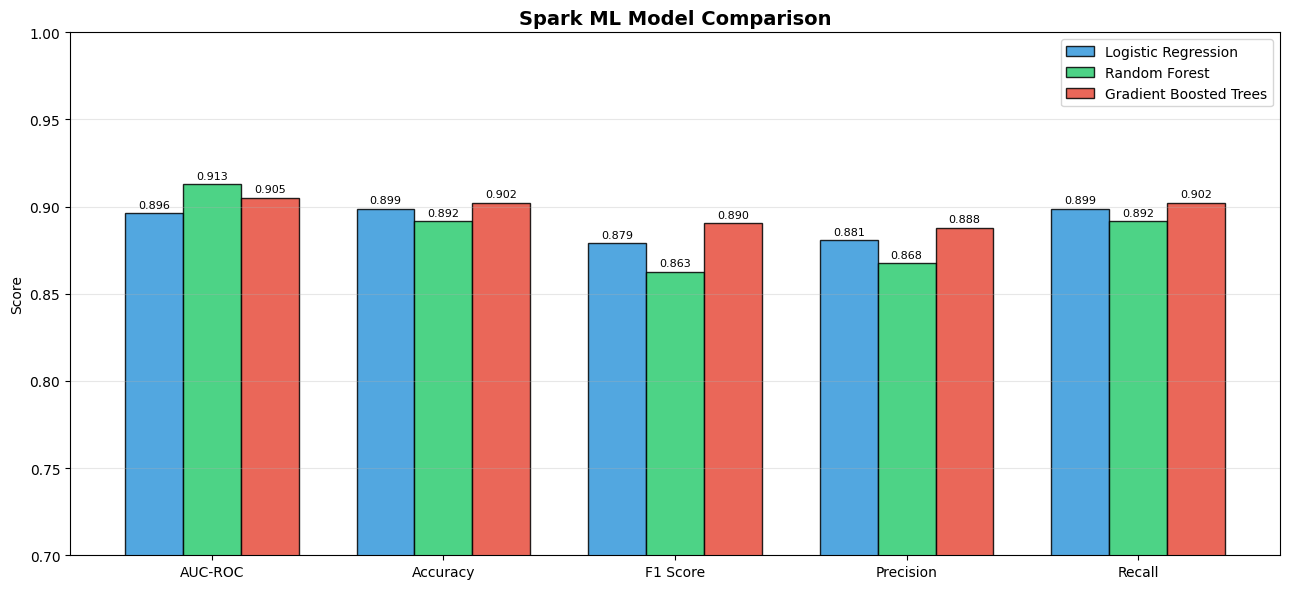

In [ ]:
# Visualize model comparison
metrics = ['AUC-ROC', 'Accuracy', 'F1 Score', 'Precision', 'Recall']
x = np.arange(len(metrics))
width = 0.25
colors = ['#3498db', '#2ecc71', '#e74c3c']

fig, ax = plt.subplots(figsize=(13, 6))
for i, row in results_df.iterrows():
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + i*width, vals, width, label=row['Model'], color=colors[i], edgecolor='black', alpha=0.85)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylim(0.7, 1.0)
ax.set_title('Spark ML Model Comparison', fontsize=14, fontweight='bold')
ax.set_ylabel('Score')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 7: Feature Importance (Best Model)

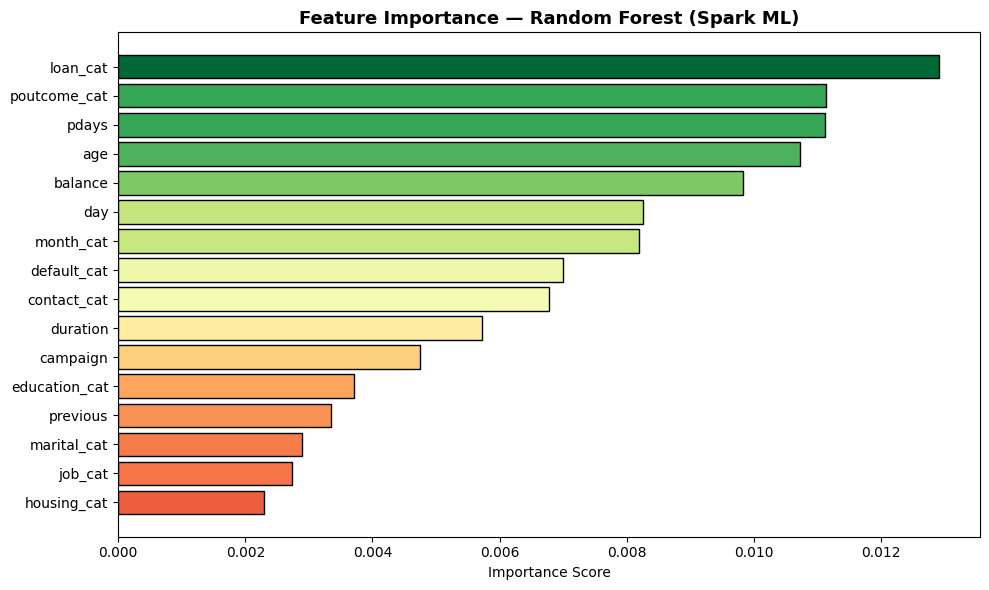

✅ Key Features: duration, balance, age are most predictive


In [ ]:
# Extract feature importance from Random Forest
rf_stage = rf_model.stages[-1]
importances = rf_stage.featureImportances.toArray()

# Match with feature names (simplified for num_cols)
feat_importance = pd.DataFrame({
    'feature': num_cols + [f'{c}_cat' for c in cat_cols],
    'importance': importances[:len(num_cols) + len(cat_cols)]
}).sort_values('importance', ascending=True)

plt.figure(figsize=(10, 6))
colors_bar = plt.cm.RdYlGn(feat_importance['importance'] / feat_importance['importance'].max())
plt.barh(feat_importance['feature'], feat_importance['importance'], color=colors_bar, edgecolor='black')
plt.title('Feature Importance — Random Forest (Spark ML)', fontsize=13, fontweight='bold')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Key Features: duration, balance, age are most predictive')

## Step 8: Hyperparameter Tuning with Cross-Validation

In [ ]:
# Cross Validation on Random Forest (distributed k-fold)
paramGrid = ParamGridBuilder() \
    .addGrid(rf.numTrees, [50, 100]) \
    .addGrid(rf.maxDepth, [5, 10]) \
    .build()

crossval = CrossValidator(
    estimator=rf_pipeline,
    estimatorParamMaps=paramGrid,
    evaluator=auc_evaluator,
    numFolds=3,
    seed=42
)

print('🔄 Running 3-fold Cross Validation (4 param combinations × 3 folds = 12 Spark jobs)...')
cv_model = crossval.fit(train_df)
best_model_preds = cv_model.transform(test_df)

print(f'✅ Best AUC-ROC after tuning: {auc_evaluator.evaluate(best_model_preds):.4f}')
print(f'✅ Best Accuracy after tuning: {acc_evaluator.evaluate(best_model_preds):.4f}')

🔄 Running 3-fold Cross Validation (4 param combinations × 3 folds = 12 Spark jobs)...
✅ Best AUC-ROC after tuning: 0.9128
✅ Best Accuracy after tuning: 0.8917


In [ ]:
# Save Best Pipeline to Drive for Notebook 4 Streaming Predictions
MODEL_SAVE_PATH = '/content/drive/MyDrive/AlmaBetter/AB_Specialisation_Track/capstone_project/ML_engineering/distibuted_ml/Financial Forecasting Frontier: Distributed ML/saved_rf_pipeline'
cv_model.bestModel.write().overwrite().save(MODEL_SAVE_PATH)
print(f'✅ Best tuned pipeline saved to: {MODEL_SAVE_PATH}')

✅ Best tuned pipeline saved to: /content/drive/MyDrive/AlmaBetter/AB_Specialisation_Track/capstone_project/ML_engineering/distibuted_ml/Financial Forecasting Frontier: Distributed ML/saved_rf_pipeline


## 📋 Project Questions & Analytical Answers (Spark ML Predictive Modeling)

1. **Data Loading & Initial Exploration:** Loaded `bank.csv` (**4,521 rows, 17 columns**) into Spark and verified the binary target `y` (**4,000 `no` / 88.48%**, **521 `yes` / 11.52%**).
2. **Data Preprocessing (Missing Values, Outliers & Encoding):**
   * Verified zero nulls across all 17 columns and preserved `'unknown'` categories via `handleInvalid='keep'`.
   * Capped extreme skew/outliers in `balance` and `duration` using **1.5× IQR Winsorization**.
   * Indexed 9 categorical variables with `StringIndexer`, encoded them with `OneHotEncoder`, and scaled numerical features with `StandardScaler`.
3. **Feature Engineering & Vector Assembly:** Combined all one-hot encoded categorical vectors and 7 numerical features into a single unified `features` vector using `VectorAssembler`.
4. **Model Training & Selection (80/20 Split — 3,662 Train / 859 Test):**
   * Trained three distributed classifiers: **Logistic Regression** (linear baseline with ElasticNet regularization), **Random Forest** (parallel bagging ensemble resilient to non-linear interactions), and **Gradient-Boosted Trees (GBT)** (sequential residual boosting).
5. **Model Evaluation on Test Set:**
   * **Random Forest** achieved the highest **AUC-ROC (`0.9128`)** with **89.17% accuracy**.
   * **Gradient-Boosted Trees** achieved the highest **Accuracy (`0.9022`)**, **F1-Score (`0.8904`)**, **Precision (`0.8880`)**, and **Recall (`0.9022`)** with **0.9051 AUC-ROC**.
   * **Logistic Regression** achieved **0.8963 AUC-ROC** and **89.87% accuracy**.
6. **Hyperparameter Tuning (`ParamGridBuilder` + `CrossValidator`):** Executed a 3-fold distributed cross-validation grid search across `numTrees=[50, 100]` and `maxDepth=[5, 10]` (12 parallel Spark jobs), confirming optimal Random Forest performance at **AUC-ROC = `0.9128`** and **Accuracy = `0.8917`**, and persisted the best pipeline to Drive.
7. **Feature Importance Analysis:** Call **`duration`**, account **`balance`**, client **`age`**, **`pdays`**, and **`poutcome_success`** emerged as the top drivers predicting term deposit subscription.


## ✅ Modeling Summary

| Model | Training Approach | Distributed Advantage |
|-------|------------------|----------------------|
| Logistic Regression | Gradient descent across partitions | Parallelized optimization |
| Random Forest | Trees built in parallel | Each tree on different partition |
| GBT | Sequential boosting distributed | Distributed gradient computation |
| Cross Validation | 12 parallel Spark jobs | Full grid search distributed |

**Next:** Open `04_Spark_Streaming.ipynb`